In [1]:
!pip install kagglehub


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


# 흉부 X-ray 분류 실험

**질문:** 사전 학습이 작은 CNN 기준 모델보다 도움이 되는가? 같은 ResNet18에서 동결 범위를 바꾸면 성능은 어떻게 달라지는가?

이 노트북은 원본 데이터를 먼저 살펴보고, 반복 가능한 분할로 모델을 학습한 뒤 검증셋으로 비교한다. 제공된 테스트셋은 마지막에 선택된 모델만 평가한다. 학습·평가 코드는 `src/`에 분리했다.


# 데이터 불러오기

In [1]:
import sys
import os
from pathlib import Path
import torch
import torch.nn as nn
import pandas as pd
import kagglehub
from torchvision import datasets
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src').exists():
    raise RuntimeError('프로젝트 루트 또는 notebooks 폴더에서 실행하세요.')
sys.path.insert(0, str(PROJECT_ROOT))
from src.data import make_loaders
from src.model import create_model
from src.experiment import load_or_train
from src.evaluate import evaluate, plot_confusion_matrix, plot_loss_history


In [2]:
# Download latest version
dataset_root = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Dataset path:", dataset_root)

Dataset path: /Users/yundong-ug/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2


In [3]:
# GPU 설정
device = torch.device("mps" if torch.mps.is_available() else "cpu")
print(device)

mps


In [4]:
train_dir = os.path.join(dataset_root, "chest_xray", "train")
val_dir = os.path.join(dataset_root, "chest_xray", "val")
test_dir = os.path.join(dataset_root, "chest_xray", "test")

# transform 전에 원본 데이터 확인

In [5]:
train_dataset = datasets.ImageFolder(train_dir)

In [6]:
image_path, label = train_dataset.samples[0]

with Image.open(image_path) as img:
    print(image_path)
    print(img.size)  # (가로 픽셀, 세로 픽셀)

/Users/yundong-ug/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/train/NORMAL/IM-0115-0001.jpeg
(2090, 1858)


In [7]:
sizes = Counter()
for image_path, _ in train_dataset.samples:
    with Image.open(image_path) as img:
        sizes[img.size] += 1

train_data_size_table = pd.DataFrame(
    [(width, height, count) for (width, height), count in sizes.items()],
    columns=["width", "height", "count"]
).sort_values("count", ascending=False).reset_index(drop=True)

In [8]:
train_data_size_table.describe()

,width,height,count
count,4366.000000,4366.000000,4366.000000
mean,1354.620705,1005.840357,1.194686
std,369.080580,394.074698,0.536954
min,384.000000,127.000000,1.000000
25%,1080.000000,712.000000,1.000000
50%,1336.000000,955.000000,1.000000
75%,1600.000000,1248.000000,1.000000
max,2916.000000,2663.000000,7.000000


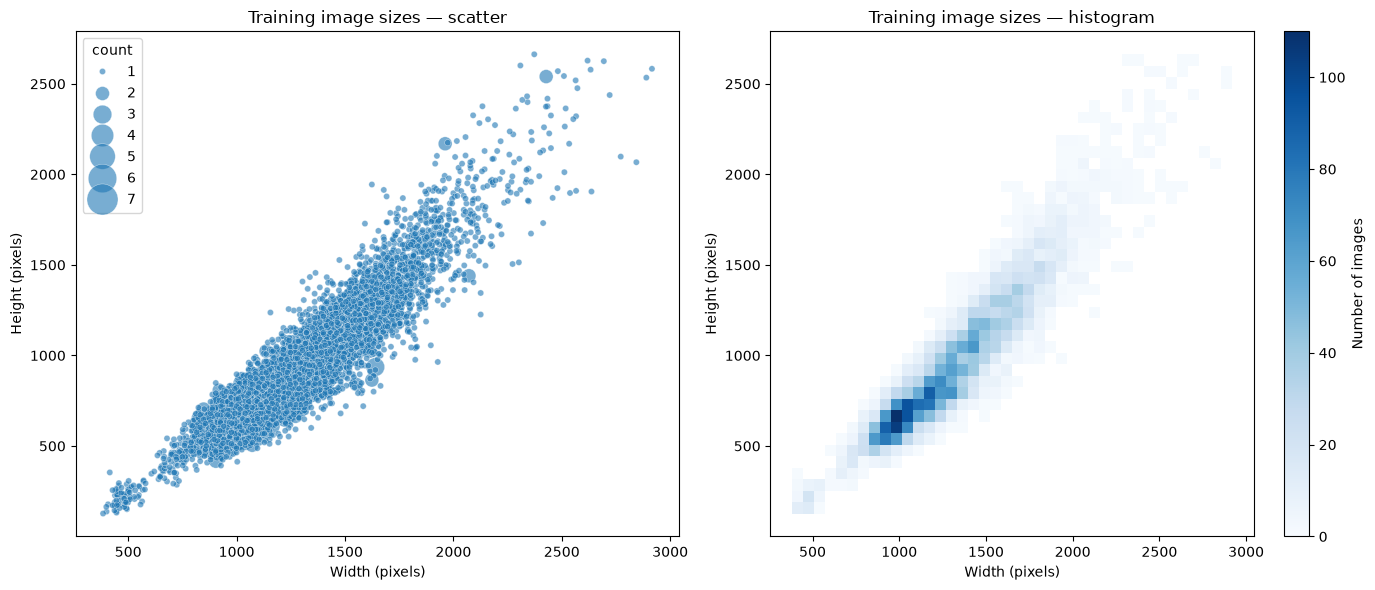

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(
    data=train_data_size_table,
    x="width",
    y="height",
    size="count",
    sizes=(20, 500),
    alpha=0.6,
    legend="brief",
    ax=axes[0],
)

axes[0].set_title("Training image sizes — scatter")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Height (pixels)")

sns.histplot(
    data=train_data_size_table,
    x="width",
    y="height",
    weights="count",
    bins=40,
    cmap="Blues",
    cbar=True,
    cbar_kws={"label": "Number of images"},
    ax=axes[1],
)
axes[1].set_title("Training image sizes — histogram")
axes[1].set_xlabel("Width (pixels)")
axes[1].set_ylabel("Height (pixels)")

fig.tight_layout()
plt.show()

In [10]:
class_counts = (
    pd.Series(train_dataset.targets)
    .map(dict(enumerate(train_dataset.classes)))
    .value_counts()
)

class_table = pd.DataFrame({
    "class": class_counts.index,
    "count": class_counts.values,
    "percent": class_counts.values / class_counts.sum() * 100
})

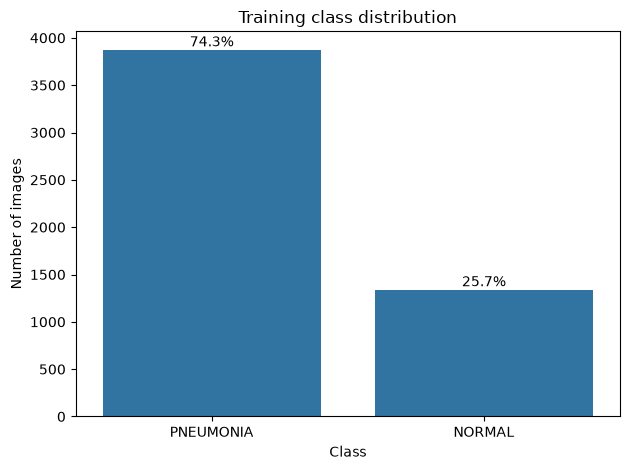

In [11]:
ax = sns.barplot(data=class_table, x="class", y="count")

for bar, percent in zip(ax.patches, class_table["percent"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percent:.1f}%",
        ha="center",
        va="bottom"
    )

ax.set(xlabel="Class", ylabel="Number of images", title="Training class distribution")
plt.tight_layout()
plt.show()

## 환자 단위 검증셋 재구성

원래 train과 작은 val을 합친 뒤 파일명에서 환자 ID를 추출하여 `StratifiedGroupKFold`로 약 80:20 분리한다. 같은 환자는 train과 validation 양쪽에 들어가지 않는다. 클래스 비율을 확인하고 분할 seed를 고정한다. 제공된 test는 분할에 참여하지 않는다.


In [12]:
SEED = 42
BATCH_SIZE = 32
EPOCHS = 10
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', device)

# scratch 모델용 전처리
scratch_data = make_loaders(dataset_root, batch_size=BATCH_SIZE, seed=SEED, augment=False, pretrained=False)
class_names = scratch_data['classes']
print('classes:', class_names, 'sizes:', scratch_data['sizes'])
print('split:', scratch_data['split'])
# 다수 클래스로만 예측했을 때의 기준 정확도
raw_train = datasets.ImageFolder(train_dir)
raw_val = datasets.ImageFolder(val_dir)
all_targets = raw_train.targets + raw_val.targets
majority_baseline = max(Counter(all_targets).values()) / len(all_targets)
print('majority-class baseline:', round(majority_baseline, 3))


device: mps
classes: ['NORMAL', 'PNEUMONIA'] sizes: {'train': 4185, 'val': 1047, 'test': 624}
split: {'strategy': 'stratified_patient_group', 'seed': 42, 'train_patients': 2288, 'val_patients': 573, 'patient_overlap': 0}
majority-class baseline: 0.742


### Train과 validation에 완전히 같은 파일이 있는가?

SHA-256으로 **파일 내용이 완전히 같은 경우**만 찾는다. 중복이 있으면 훈련셋은 유지하고 검증셋에서만 제외한다. 파일명이 다른 동일 파일도 탐지할 수 있지만, 리사이즈·재인코딩된 유사 이미지는 이 방법으로 탐지하지 못한다.


In [13]:
import hashlib
from torch.utils.data import DataLoader, Subset

def sha256_file(file_path):
    digest = hashlib.sha256()
    with open(file_path, 'rb') as image_file:
        for chunk in iter(lambda: image_file.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def sample_path(subset, index):
    # Subset(ConcatDataset([original_train, original_val])) 구조에서 경로 찾기
    sources = subset.dataset.datasets
    if index < len(sources[0]):
        return sources[0].samples[index][0]
    return sources[1].samples[index - len(sources[0])][0]

train_subset = scratch_data['train'].dataset
val_subset = scratch_data['val'].dataset
train_hashes = {}
for index in train_subset.indices:
    image_path = sample_path(train_subset, index)
    train_hashes.setdefault(sha256_file(image_path), image_path)

kept_val_indices = []
duplicate_pairs = []
for index in val_subset.indices:
    image_path = sample_path(val_subset, index)
    digest = sha256_file(image_path)
    if digest in train_hashes:
        duplicate_pairs.append((train_hashes[digest], image_path))
    else:
        kept_val_indices.append(index)

print(f"train/validation 중복: {len(duplicate_pairs)}개")
if duplicate_pairs:
    display(pd.DataFrame(duplicate_pairs, columns=['train_path', 'val_path']))
    if not kept_val_indices:
        raise ValueError('중복 제거 후 validation이 비어 있습니다.')
    scratch_data['val'] = DataLoader(
        Subset(val_subset.dataset, kept_val_indices),
        batch_size=scratch_data['val'].batch_size, shuffle=False,
        num_workers=scratch_data['val'].num_workers,
    )
    scratch_data['sizes']['val'] = len(kept_val_indices)
print('필터링 후 validation:', scratch_data['sizes']['val'])


train/validation 중복: 0개
필터링 후 validation: 1047


In [14]:
# 이전 셀에서 찾은 동일 파일 쌍을 나란히 확인한다.
max_pairs_to_show = 8
if duplicate_pairs:
    shown_pairs = duplicate_pairs[:max_pairs_to_show]
    fig, axes = plt.subplots(len(shown_pairs), 2, figsize=(10, 4 * len(shown_pairs)), squeeze=False)
    for row, (train_path, val_path) in enumerate(shown_pairs):
        for col, image_path in enumerate((train_path, val_path)):
            with Image.open(image_path) as image:
                axes[row, col].imshow(image, cmap='gray')
            axes[row, col].set_title(f"{'train' if col == 0 else 'validation'}: {Path(image_path).name}")
            axes[row, col].axis('off')
    plt.tight_layout()
    plt.show()
    if len(duplicate_pairs) > max_pairs_to_show:
        print(f"나머지 {len(duplicate_pairs) - max_pairs_to_show}쌍은 경로 표에서 확인하세요.")
else:
    print('파일 내용이 완전히 같은 train/validation 이미지는 없습니다.')


파일 내용이 완전히 같은 train/validation 이미지는 없습니다.


## 작은 CNN 기준 모델

사전 학습 없이 훈련한 모델을 기준으로 삼는다. 검증셋에서 오류를 분석한 뒤 증강 또는 모델 구조 실험으로 이어간다.

각 에폭의 train/validation loss·accuracy·precision·recall·F1·혼동 행렬은 `outputs/experiments/`의 CSV에 저장한다. Precision, Recall, F1의 양성 클래스는 `PNEUMONIA`이다.

환자 단위로 분할이 바뀌었으므로 이전 이미지 단위 분할 체크포인트는 재사용하지 않는다.


In [15]:
torch.manual_seed(SEED)
criterion = nn.CrossEntropyLoss()
scratch_model, scratch_history, scratch_reused = load_or_train(
    'custom_cnn', num_classes=len(class_names), pretrained=False, mode='full',
    train_loader=scratch_data['train'], val_loader=scratch_data['val'],
    criterion=criterion, device=device, epochs=EPOCHS, lr=1e-3, seed=SEED,
    output_dir=PROJECT_ROOT / 'outputs' / 'experiments',
)
print('기존 실험 재사용:', scratch_reused)


Epoch 1/10 | train loss 0.2685, acc 0.887, P/R/F1 0.896/0.959/0.927 | val loss 0.1598, acc 0.935, P/R/F1 0.937/0.978/0.957
Epoch 2/10 | train loss 0.1423, acc 0.945, P/R/F1 0.961/0.966/0.963 | val loss 0.1165, acc 0.956, P/R/F1 0.955/0.987/0.971
Epoch 3/10 | train loss 0.1174, acc 0.956, P/R/F1 0.969/0.971/0.970 | val loss 0.0944, acc 0.962, P/R/F1 0.977/0.972/0.974
Epoch 4/10 | train loss 0.0951, acc 0.966, P/R/F1 0.977/0.977/0.977 | val loss 0.0889, acc 0.968, P/R/F1 0.988/0.968/0.978
Epoch 5/10 | train loss 0.0913, acc 0.966, P/R/F1 0.976/0.979/0.977 | val loss 0.1292, acc 0.950, P/R/F1 0.993/0.940/0.966
Epoch 6/10 | train loss 0.0834, acc 0.972, P/R/F1 0.982/0.980/0.981 | val loss 0.0897, acc 0.962, P/R/F1 0.959/0.991/0.975
Epoch 7/10 | train loss 0.0831, acc 0.968, P/R/F1 0.977/0.979/0.978 | val loss 0.0821, acc 0.969, P/R/F1 0.969/0.991/0.980
Epoch 8/10 | train loss 0.0745, acc 0.972, P/R/F1 0.982/0.981/0.981 | val loss 0.0676, acc 0.975, P/R/F1 0.978/0.988/0.983
Epoch 9/10 | tra

,epoch,train_loss,train_accuracy,train_precision,train_recall,train_f1,train_confusion_matrix,train_tn,train_fp,train_fn,...,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_confusion_matrix,val_tn,val_fp,val_fn,val_tp
0,1,0.268507,0.887216,0.896448,0.958789,0.926571,"[[735, 344], [128, 2978]]",735,344,128,...,0.159823,0.935053,0.937115,0.978121,0.957179,"[[219, 51], [17, 760]]",219,51,17,760
1,2,0.142341,0.945281,0.960910,0.965551,0.963225,"[[957, 122], [107, 2999]]",957,122,107,...,0.116489,0.956065,0.955168,0.987130,0.970886,"[[234, 36], [10, 767]]",234,36,10,767
2,3,0.117375,0.955556,0.968850,0.971346,0.970096,"[[982, 97], [89, 3017]]",982,97,89,...,0.094364,0.961796,0.976714,0.971686,0.974194,"[[252, 18], [22, 755]]",252,18,22,755
3,4,0.095090,0.966308,0.977456,0.977141,0.977298,"[[1009, 70], [71, 3035]]",1009,70,71,...,0.088902,0.967526,0.988173,0.967825,0.977893,"[[261, 9], [25, 752]]",261,9,25,752
4,5,0.091307,0.966308,0.975923,0.978751,0.977335,"[[1004, 75], [66, 3040]]",1004,75,66,...,0.129233,0.950334,0.993197,0.939511,0.965608,"[[265, 5], [47, 730]]",265,5,47,730
5,6,0.083421,0.971804,0.981625,0.980361,0.980992,"[[1022, 57], [61, 3045]]",1022,57,61,...,0.089700,0.961796,0.958904,0.990991,0.974684,"[[237, 33], [7, 770]]",237,33,7,770
6,7,0.083136,0.967742,0.977499,0.979073,0.978285,"[[1009, 70], [65, 3041]]",1009,70,65,...,0.082144,0.969436,0.968553,0.990991,0.979644,"[[245, 25], [7, 770]]",245,25,7,770
7,8,0.074470,0.972282,0.981637,0.981005,0.981320,"[[1022, 57], [59, 3047]]",1022,57,59,...,0.067607,0.975167,0.978344,0.988417,0.983355,"[[253, 17], [9, 768]]",253,17,9,768
8,9,0.075524,0.970609,0.980664,0.979717,0.980190,"[[1019, 60], [63, 3043]]",1019,60,63,...,0.094560,0.957020,0.947433,0.997426,0.971787,"[[227, 43], [2, 775]]",227,43,2,775
9,10,0.067109,0.975388,0.984199,0.982614,0.983406,"[[1030, 49], [54, 3052]]",1030,49,54,...,0.064623,0.972302,0.974619,0.988417,0.981470,"[[250, 20], [9, 768]]",250,20,9,768


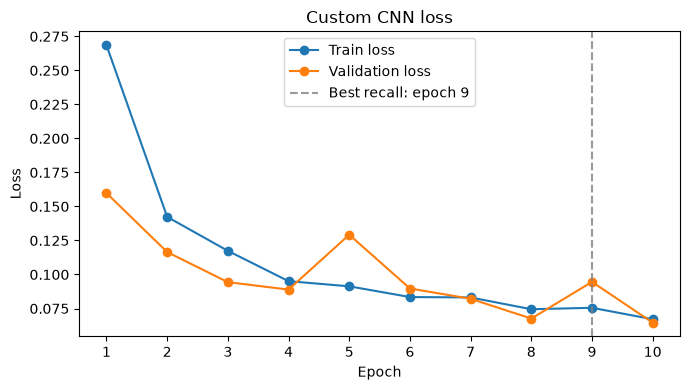

              precision    recall  f1-score     support
NORMAL         0.991266  0.840741  0.909820   270.00000
PNEUMONIA      0.947433  0.997426  0.971787   777.00000
accuracy       0.957020  0.957020  0.957020     0.95702
macro avg      0.969350  0.919083  0.940803  1047.00000
weighted avg   0.958737  0.957020  0.955807  1047.00000


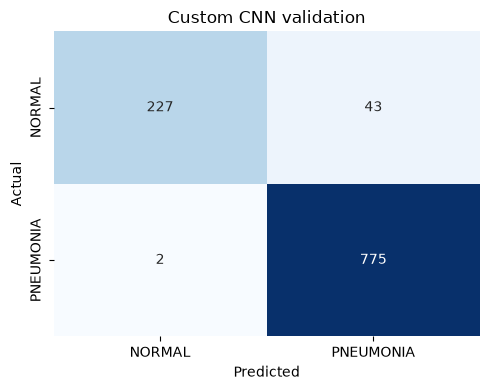

In [17]:
display(pd.DataFrame(scratch_history))
plot_loss_history(scratch_history, 'Custom CNN loss')
plt.show()
scratch_val = evaluate(scratch_model, scratch_data['val'], criterion, device, class_names)
print(pd.DataFrame(scratch_val['report']).T)
plot_confusion_matrix(scratch_val['confusion_matrix'], class_names, 'Custom CNN validation')
plt.show()

## ResNet18 전이학습: Frozen / Partial / Full

모든 실험은 동일한 데이터 분할을 사용한다. 각 실험은 새 pretrained 가중치에서 시작하고, 해당 모델에서 학습 가능한 파라미터만 옵티마이저에 전달한다. pretrained 가중치에 맞춰 3채널과 ImageNet 정규화를 적용한다.

검증 Recall이 좋아질 때마다 최고 가중치를 `outputs/experiments/`에 저장한다. Recall 동률이면 F1, 그다음 validation loss로 고른다. 학습 종료 후 모델은 최고 가중치로 복원된다.


In [ ]:
pretrained_data = make_loaders(dataset_root, batch_size=BATCH_SIZE, seed=SEED,
                               augment=False, pretrained=True)
assert pretrained_data['classes'] == class_names
# scratch 실험과 동일한 검증 샘플을 사용한다.
if duplicate_pairs:
    original_val_loader = pretrained_data['val']
    pretrained_data['val'] = DataLoader(
        Subset(original_val_loader.dataset.dataset, kept_val_indices),
        batch_size=original_val_loader.batch_size, shuffle=False,
        num_workers=original_val_loader.num_workers,
    )
    pretrained_data['sizes']['val'] = len(kept_val_indices)
experiments = {}
for mode, lr in [('frozen', 1e-3), ('partial', 1e-4), ('full', 1e-5)]:
    torch.manual_seed(SEED)
    net, history, reused = load_or_train(
        'resnet18', num_classes=len(class_names), pretrained=True, mode=mode,
        train_loader=pretrained_data['train'], val_loader=pretrained_data['val'],
        criterion=criterion, device=device, epochs=EPOCHS, lr=lr, seed=SEED,
        output_dir=PROJECT_ROOT / 'outputs' / 'experiments',
    )
    print(mode, '기존 실험 재사용:', reused)
    metrics = evaluate(net, pretrained_data['val'], criterion, device, class_names)
    experiments[mode] = {'model': net, 'history': history, 'validation': metrics}
    plot_loss_history(history, f'ResNet18 {mode} loss')
    plt.show()
    print(mode, 'validation accuracy:', round(metrics['accuracy'], 4))
    plot_confusion_matrix(metrics['confusion_matrix'], class_names, f'ResNet18 {mode} validation')
    plt.show()


## 검증 성능 비교와 최종 모델 선택

모델 선택에는 검증 결과만 사용한다. 폐렴 Recall이 높은 순서로 고르고 동률이면 F1을 본다. 정확도와 Precision도 함께 확인한다. 테스트셋은 아래에서 선택된 모델에 대해 한 번 평가한다.


In [ ]:
positive_class = 'PNEUMONIA'
rows = []
for mode, result in experiments.items():
    m = result['validation']
    p = m['report'][positive_class]
    rows.append({'model': mode, 'accuracy': m['accuracy'], 'precision': p['precision'],
                 'recall': p['recall'], 'f1': p['f1-score']})
comparison = pd.DataFrame(rows).set_index('model').sort_values(['recall', 'f1'], ascending=False)
display(comparison)
best_mode = comparison.index[0]
print('선택한 모델:', best_mode)


In [ ]:
final_model = experiments[best_mode]['model']
test_metrics = evaluate(final_model, pretrained_data['test'], criterion, device, class_names)
print('test accuracy:', round(test_metrics['accuracy'], 4))
display(pd.DataFrame(test_metrics['report']).T)
plot_confusion_matrix(test_metrics['confusion_matrix'], class_names, 'Selected model test')
plt.show()


## 다음 실험

1. 검증셋의 확신도 높은 오답을 확인하고 오류 유형을 기록한다.
2. AlexNet·VGG·GoogLeNet·ResNet 직접 구현 모델을 `create_model(name, num_classes=2, pretrained=False)`로 생성해 **같은 분할과 평가 함수**로 비교한다.
3. 약한 증강을 하나씩 적용해 검증 성능 변화와 오답 변화를 본다.
4. 가장 유망한 모델에만 Optuna를 적용한다. Optuna 역시 검증셋만 사용한다.

**결과 해석:** 위 표를 실행한 뒤 성능 차이, 오답 유형, 최종 모델을 고른 이유를 여기에 적는다.
